# 03 - Analyse des ventes Superstore

On répond aux 5 questions à partir du fichier propre `data/processed/ventes_propres.csv`.

1. Comment les ventes évoluent-elles par mois et par année ?
2. Quelle catégorie de produits rapporte le plus de profit ?
3. Les remises font-elles baisser le profit ?
4. Quelle région vend le plus ?
5. Combien de jours passent en moyenne entre la commande et l'expédition ?

In [127]:
import pandas as pd
import matplotlib.pyplot as plt

ventes = pd.read_csv(
    "../data/processed/ventes_propres.csv",
    dtype={"Postal Code": str},
    parse_dates=["Order Date", "Ship Date"],
)
ventes.shape

(9993, 20)

In [128]:
ventes_par_annee = ventes.groupby(ventes["Order Date"].dt.year)["Sales"].sum()
ventes_par_annee

Order Date
2014    483966.1261
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64

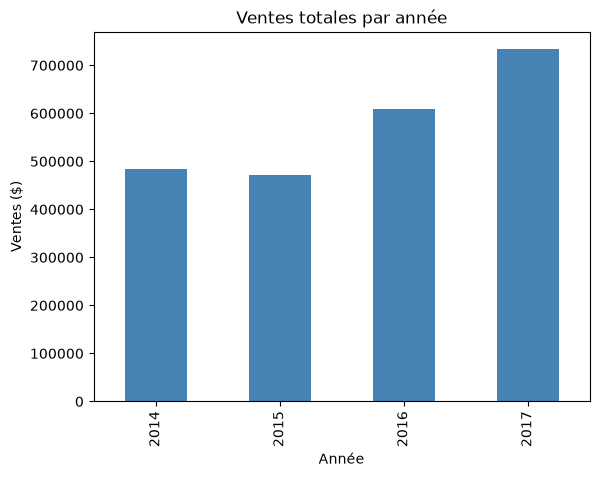

In [129]:
ventes_par_annee.plot(kind="bar", color="steelblue")
plt.title("Ventes totales par année")
plt.xlabel("Année")
plt.ylabel("Ventes ($)")
plt.savefig("../figures/ventes_par_annee.png", bbox_inches="tight")
plt.show()

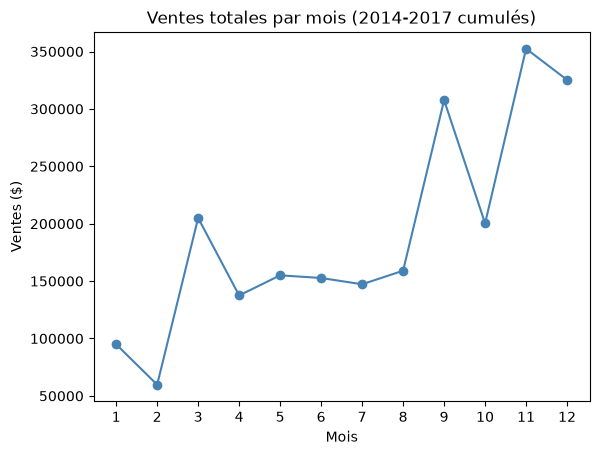

In [130]:
ventes_par_mois = ventes.groupby(ventes["Order Date"].dt.month)["Sales"].sum()

ventes_par_mois.plot(kind="line", marker="o", color="steelblue")
plt.title("Ventes totales par mois (2014-2017 cumulés)")
plt.xlabel("Mois")
plt.ylabel("Ventes ($)")
plt.xticks(range(1, 13))
plt.savefig("../figures/ventes_par_mois.png", bbox_inches="tight")
plt.show()

### Réponse 1 : évolution des ventes

- **Par année :** les ventes baissent un peu en 2015 (-3 %), puis augmentent fortement : 470 k$ en 2015 → 733 k$ en 2017 (**+56 %**).
- **Par mois :** les ventes sont faibles en janvier-février et très fortes en **septembre, novembre et décembre** (rentrée et fêtes de fin d'année). Novembre est le meilleur mois (352 k$), février le plus faible (60 k$).

In [131]:
par_categorie = ventes.groupby("Category")[["Sales", "Profit"]].sum()
par_categorie = par_categorie.sort_values("Profit", ascending=False)
par_categorie

,Sales,Profit
Category,,
Technology,836154.0330,145454.9481
Office Supplies,719047.0320,122490.8008
Furniture,741718.4233,18463.3316


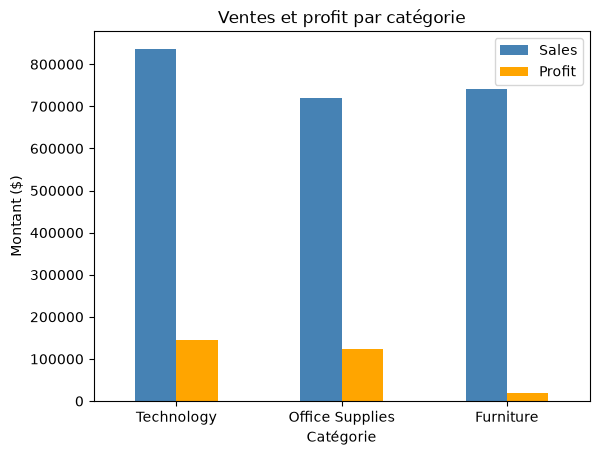

In [132]:
par_categorie.plot(kind="bar", color=["steelblue", "orange"])
plt.title("Ventes et profit par catégorie")
plt.xlabel("Catégorie")
plt.ylabel("Montant ($)")
plt.xticks(rotation=0)
plt.savefig("../figures/profit_par_categorie.png", bbox_inches="tight")
plt.show()

### Réponse 2 : la catégorie la plus rentable

- **Technology** rapporte le plus de profit : **145 k$**, soit 17 % de ses ventes.
- **Office Supplies** suit avec 122 k$ (17 % aussi).
- **Furniture** vend presque autant que les autres (742 k$) mais ne rapporte que **18 k$** (2 % de ses ventes).

Vendre beaucoup ne veut pas dire gagner beaucoup : les meubles font du chiffre, mais presque pas de bénéfice.

In [133]:
profit_par_remise = ventes.groupby("Discount")["Profit"].mean()
profit_par_remise

Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.828401
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64

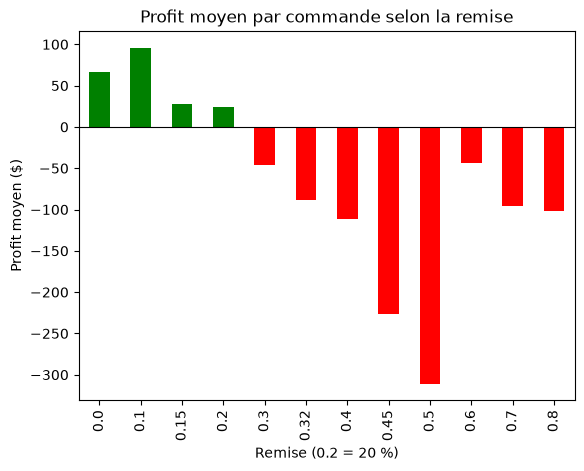

In [134]:
couleurs = ["green" if p > 0 else "red" for p in profit_par_remise]

profit_par_remise.plot(kind="bar", color=couleurs)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Profit moyen par commande selon la remise")
plt.xlabel("Remise (0.2 = 20 %)")
plt.ylabel("Profit moyen ($)")
plt.savefig("../figures/profit_par_remise.png", bbox_inches="tight")
plt.show()

### Réponse 3 : l'effet des remises

**Oui, les remises font baisser le profit.**

- Jusqu'à **20 %** de remise, les commandes restent rentables (profit moyen entre +25 $ et +96 $).
- À partir de **30 %**, chaque commande fait **perdre** de l'argent en moyenne.
- La pire remise est **50 %** : -311 $ par commande en moyenne.

Conseil : ne pas dépasser 20 % de remise.

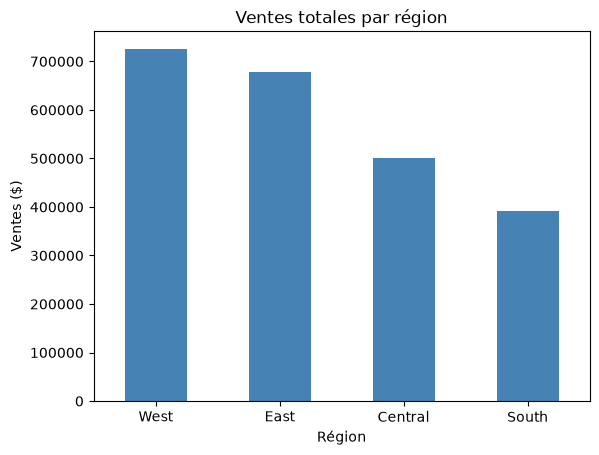

In [135]:
par_region = ventes.groupby("Region")["Sales"].sum().sort_values(ascending=False)

par_region.plot(kind="bar", color="steelblue")
plt.title("Ventes totales par région")
plt.xlabel("Région")
plt.ylabel("Ventes ($)")
plt.xticks(rotation=0)
plt.savefig("../figures/ventes_par_region.png", bbox_inches="tight")
plt.show()

### Réponse 4 : la région qui vend le plus

- **West** vend le plus : **725 k$**, soit 32 % des ventes.
- Puis East (679 k$, 30 %), Central (501 k$, 22 %) et South (392 k$, 17 %).

Les deux côtes (West et East) font à elles seules plus de 60 % des ventes.

In [136]:
ventes["Délai (jours)"] = (ventes["Ship Date"] - ventes["Order Date"]).dt.days

print("Délai moyen :", round(ventes["Délai (jours)"].mean(), 1), "jours")
ventes.groupby("Ship Mode")["Délai (jours)"].mean().sort_values()

Délai moyen : 4.0 jours


Ship Mode
Same Day          0.044199
First Class       2.182705
Second Class      3.238046
Standard Class    5.006704
Name: Délai (jours), dtype: float64

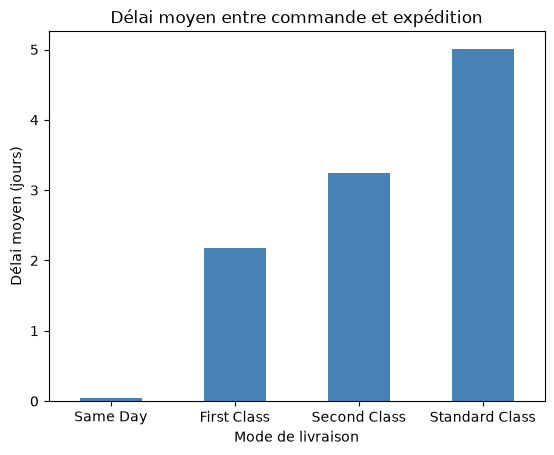

In [137]:
delai_par_mode = ventes.groupby("Ship Mode")["Délai (jours)"].mean().sort_values()

delai_par_mode.plot(kind="bar", color="steelblue")
plt.title("Délai moyen entre commande et expédition")
plt.xlabel("Mode de livraison")
plt.ylabel("Délai moyen (jours)")
plt.xticks(rotation=0)
plt.savefig("../figures/delai_par_mode.png", bbox_inches="tight")
plt.show()

### Réponse 5 : le délai d'expédition

- En moyenne, une commande est expédiée **4 jours** après avoir été passée (entre 0 et 7 jours).
- Le délai dépend du mode de livraison : **Same Day** le jour même, **First Class** 2,2 jours, **Second Class** 3,2 jours, **Standard Class** 5 jours.

## Conclusion générale

| Question | Réponse |
|---|---|
| 1. Évolution des ventes | +56 % entre 2015 et 2017, pics en septembre, novembre et décembre |
| 2. Catégorie la plus rentable | **Technology** (145 k$ de profit) ; Furniture vend beaucoup mais gagne peu |
| 3. Effet des remises | Au-delà de **20 %**, les commandes sont à perte en moyenne |
| 4. Région qui vend le plus | **West** (32 % des ventes) |
| 5. Délai d'expédition | **4 jours** en moyenne, de 0 à 5 jours selon le mode |

**Recommandations :** limiter les remises à 20 %, revoir les prix des meubles, et préparer les stocks avant la fin d'année.

**Limites :** les données s'arrêtent en 2017 et ne concernent que les États-Unis.